# Complex-Valued Reconstructions

> Georgios Varnavides | Oct 8 2026
>
> Sample: a 2-unit-cell SrTiO$_3$ film, and gold nanoparticles on amorphous carbon
> Sampling conditions: 0.2 A step-size for the film, 1.33 A for the gold
> Imaging conditions: 300 kV; 25 mrad and 100 A underfocus for the film, 21.9 mrad and about 350 A underfocus for the gold
> Dose conditions: 1e5 e/A2 for the film

The notebooks so far reconstructed the phase alone. A specimen that absorbs, or whose thickness
turns phase into amplitude, also changes the amplitude of the transmitted wave, and a pure-phase
model has to explain that as phase. This notebook adds a log-amplitude channel, on a simulated
SrTiO$_3$ film with a known phase and on the experimental gold nanoparticles of
`ptycho_direct_05_gold_nanoparticles`.

In [1]:
# %load_ext autoreload
# %autoreload 2

In [2]:
import numpy as np

import quantem as em

/Users/gvarnavides/Documents/git-repos/quantem-upstream/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## The forward model

A complex object $t(\mathbf{r}) = \exp\left(a(\mathbf{r}) + i\phi(\mathbf{r})\right)$ with a weak
log-amplitude $a$ adds a second term to the model of `ptycho_direct_01_kernels`:

$$G(\mathbf{q}, \mathbf{k}) = \Gamma^+(\mathbf{q}, \mathbf{k})\, \tilde a(\mathbf{q})
+ \Gamma^-(\mathbf{q}, \mathbf{k})\, i\tilde\phi(\mathbf{q}), \qquad
\Gamma^\mp(\mathbf{q}, \mathbf{k}) = \psi(\mathbf{k} - \mathbf{q})\,\psi^*(\mathbf{k})
\mp \psi^*(\mathbf{k} + \mathbf{q})\,\psi(\mathbf{k}),$$

where $\tilde a$ is the spectrum of the log-amplitude and $\Gamma^-$ is the $\Gamma$ of the
pure-phase model. Where the aperture overlaps only one of its shifted copies, one of the two
products vanishes, so $\Gamma^+ = \pm\Gamma^-$ there and phase and amplitude arrive with
opposite relative signs on the two sides. That is what separates them.
`reconstruct(obj_type="complex")` solves for both at every spatial frequency. The phase is
stored in `corrected_bf` as before, the zero-mean log-amplitude in `corrected_amplitude`, and
`obj` returns $t$ itself.

In [3]:
def add_poisson_noise(dataset, electrons_per_area, seed=2025):
    rng = np.random.default_rng(seed)
    electrons_per_probe = electrons_per_area * np.prod(dataset.sampling[-4:-2])
    dataset_noisy = dataset.copy()
    dataset_noisy.array = rng.poisson(dataset.array * electrons_per_probe).astype(np.float32)
    return dataset_noisy


def correlation(a, b):
    a, b = (np.asarray(x.cpu() if hasattr(x, "cpu") else x, dtype=np.float64) for x in (a, b))
    a, b = a - a.mean(), b - b.mean()
    return float((a * b).sum() / np.sqrt((a * a).sum() * (b * b).sum()))

In [4]:
kwargs = dict(
    energy=300e3,
    semiangle_cutoff=25,
    rotation_angle=0,
    aberration_coefs={"C10": -100},
    verbose=False,
    # device='gpu',
)

## A simulated film

The 2-unit-cell film of `ptycho_direct_01_kernels`, at 1e5 electrons per square Angstrom,
reconstructed with OBF as a pure-phase object and as a complex one:

pure phase: residual 0.5785, correlation 0.894
complex:    residual 0.5432, correlation 0.881
obj: complex64, |obj| = exp(corrected_amplitude): True


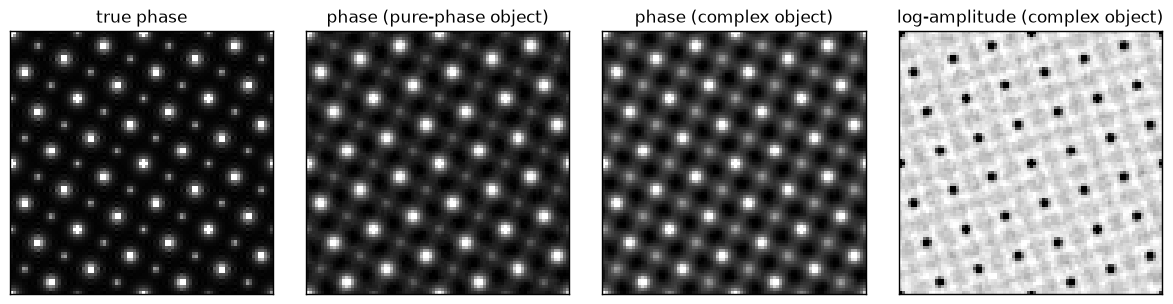

In [5]:
film = em.core.io.load("../../data/STO-film_300kV_25mrad.zip")
film_truth = em.core.io.load("../../data/STO-film_truth.zip").array[0]

direct_ptycho = em.diffractive_imaging.DirectPtychography.from_dataset4d(
    add_poisson_noise(film, 1e5), **kwargs
)

pure_phase = direct_ptycho.reconstruct(deconvolution_kernel="obf").corrected_bf.cpu().numpy()
print(f"pure phase: residual {direct_ptycho.residual_loss():.4f}, correlation {correlation(pure_phase, film_truth):.3f}")

direct_ptycho.reconstruct(deconvolution_kernel="obf", obj_type="complex")
phase = direct_ptycho.corrected_bf.cpu().numpy()
log_amplitude = direct_ptycho.corrected_amplitude.cpu().numpy()
print(f"complex:    residual {direct_ptycho.residual_loss():.4f}, correlation {correlation(phase, film_truth):.3f}")
print(f"obj: {direct_ptycho.obj.dtype}, |obj| = exp(corrected_amplitude): "
      f"{np.allclose(np.abs(direct_ptycho.obj), np.exp(log_amplitude), rtol=1e-4)}")

em.visualization.show_2d(
    [film_truth, pure_phase, phase, log_amplitude],
    title=["true phase", "phase (pure-phase object)", "phase (complex object)", "log-amplitude (complex object)"],
    axsize=(3, 3),
);

The log-amplitude is dark at the strongest columns. The film is not a weak phase object, and the
amplitude channel explains part of the data the pure-phase model could not: the residual falls
from 0.579 to 0.543. The OBF phase stays about as close to the truth, 0.881 against 0.894.

### Kernels

Every kernel but parallax returns a complex object. SSB takes it from its two sidebands, WDD
from the transmission function it deconvolves, and iCoM takes the log-amplitude from the plain
bright-field sum. Parallax raises, since aligning the images collapses the two sidebands onto
each other. `_reconstruct_all_permutations(obj_type="complex")` leaves it out, and here we run
the other five one at a time to keep their phase and log-amplitude apart:

     ssb: correlation of the phase with the truth 0.936
     obf: correlation of the phase with the truth 0.881
  wiener: correlation of the phase with the truth 0.939
     wdd: correlation of the phase with the truth 0.946
    icom: correlation of the phase with the truth -0.186


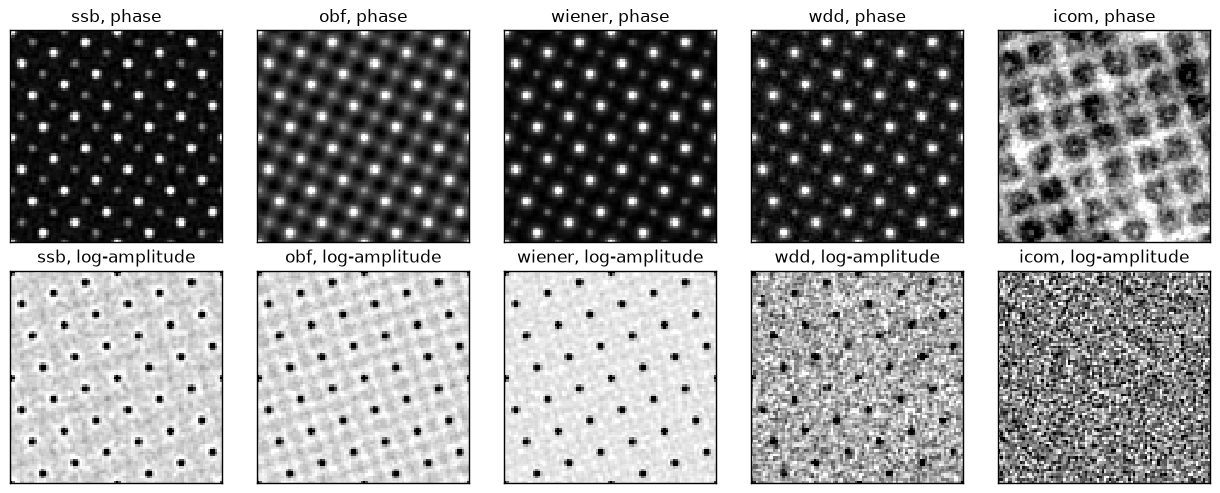

In [6]:
complex_kernels = ["ssb", "obf", "wiener", "wdd", "icom"]
phases, amplitudes = [], []
for kernel in complex_kernels:
    direct_ptycho.reconstruct(deconvolution_kernel=kernel, obj_type="complex")
    phases.append(direct_ptycho.corrected_bf.cpu().numpy())
    amplitudes.append(direct_ptycho.corrected_amplitude.cpu().numpy())
    print(f"{kernel:>8}: correlation of the phase with the truth {correlation(phases[-1], film_truth):.3f}")

em.visualization.show_2d(
    [phases, amplitudes],
    title=[[f"{kernel}, phase" for kernel in complex_kernels],
           [f"{kernel}, log-amplitude" for kernel in complex_kernels]],
    axsize=(2.5, 2.5),
);

SSB, Wiener and WDD give the cleanest phases, and SSB's is closer to the truth than its pure-phase
reconstruction in `ptycho_direct_01_kernels` (0.936 against 0.890). WDD's log-amplitude is
noisier, and iCoM's, the plain bright-field sum, shows little of the film at this defocus.

## Experimental gold nanoparticles

The gold dataset of `ptycho_direct_05_gold_nanoparticles`, binned the same way and with the
aberrations and rotation angle fitted there:

In [7]:
def bin_detector(dataset, factor):
    array = np.asarray(dataset.array, dtype=np.float32)
    ny, nx = array.shape[-2:]
    array = array[..., : ny - ny % factor, : nx - nx % factor]
    array = array.reshape(*array.shape[:2], ny // factor, factor, nx // factor, factor).sum((-3, -1))
    sampling = list(dataset.sampling[:2]) + [s * factor for s in dataset.sampling[-2:]]
    return em.core.datastructures.Dataset4dstem.from_array(
        array, sampling=sampling, units=list(dataset.units)
    )


gold = bin_detector(em.core.io.load("../../data/gold_arina_calibrated.zip"), 2)

gold_ptycho = em.diffractive_imaging.DirectPtychography.from_dataset4d(
    gold,
    energy=300e3,
    semiangle_cutoff=21.9,
    aberration_coefs={"C10": -349.2, "C12": 68.2, "phi12": 0.177},
    rotation_angle=-167.8,
    verbose=False,
    # device='gpu',
)

{'pure_phase': 0.9233, 'complex': 0.7343}


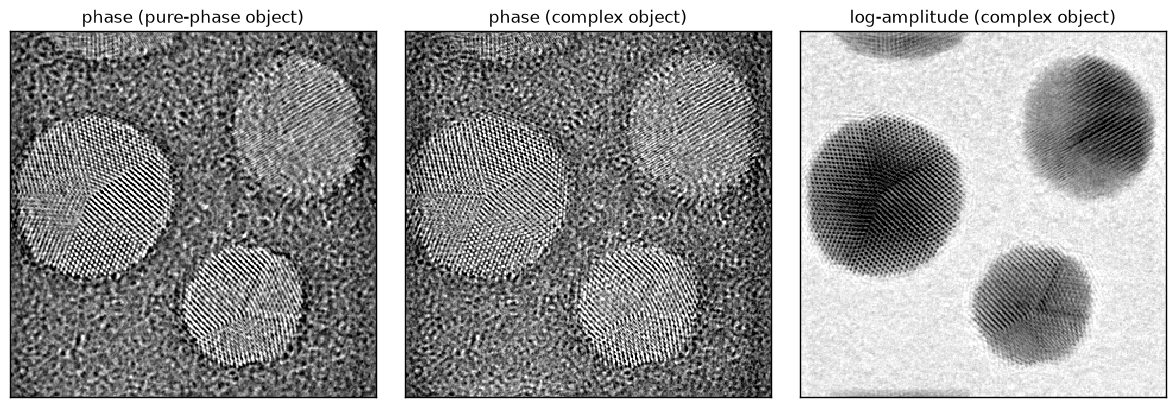

In [8]:
residuals = {}
for obj_type in ("pure_phase", "complex"):
    gold_ptycho.reconstruct(deconvolution_kernel="obf", obj_type=obj_type, verbose=False)
    residuals[obj_type] = gold_ptycho.residual_loss()
print({obj_type: round(residual, 4) for obj_type, residual in residuals.items()})

gold_pure_phase = gold_ptycho.reconstruct(
    deconvolution_kernel="obf", upsampling_factor=2, verbose=False
).corrected_bf.cpu().numpy()

gold_ptycho.reconstruct(
    deconvolution_kernel="obf", obj_type="complex", upsampling_factor=2, verbose=False
)
em.visualization.show_2d(
    [gold_pure_phase, gold_ptycho.corrected_bf.cpu().numpy(), gold_ptycho.corrected_amplitude.cpu().numpy()],
    title=["phase (pure-phase object)", "phase (complex object)", "log-amplitude (complex object)"],
    axsize=(4, 4),
);

The particles absorb, and they are dark in the log-amplitude. In the pure-phase reconstruction that
absorption has nowhere to go but the phase, where it shows as a dark halo around each particle,
and the complex reconstruction moves most of it to the log-amplitude. The amplitude channel also
explains a large part of the data the pure-phase model did not, and the residual drops from 0.92
to 0.73.

## Summary

| option | call |
|---|---|
| complex object | `reconstruct(obj_type="complex")`, then `corrected_bf`, `corrected_amplitude` and `obj` |
| kernels | every kernel but parallax |
| model comparison | `residual_loss()` of the pure-phase and complex reconstructions of the same data |

`ptycho_direct_08_multislice` adds depth: several slices, each with its own phase and
log-amplitude.